In [3]:
pip install nltk scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import re
import string
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.datasets import fetch_20newsgroups  # alternative large dataset
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
)
from sklearn.calibration import CalibratedClassifierCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
sns.set_style("whitegrid")

In [5]:
# DOWNLOAD NLTK DATA (once)
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass
print("NLTK resources ready")

NLTK resources ready


In [6]:
# LOAD DATASET — SMS Spam Collection
def load_sms_spam():
    """Downloads and loads the SMS Spam Collection (5,574 messages)."""
    import urllib.request, io, zipfile
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
    with urllib.request.urlopen(url, timeout=30) as resp:
        zf = zipfile.ZipFile(io.BytesIO(resp.read()))
        with zf.open("SMSSpamCollection") as f:
            df = pd.read_csv(f, sep="\t", header=None, names=["label", "text"],
                             encoding="latin-1")
    df["label"] = df["label"].map({"ham": 0, "spam": 1})
    return df

try:
    df = load_sms_spam()
    print(f"Loaded SMS Spam: {df.shape[0]} messages")
except Exception as e:
    print(f"Download failed ({e}). Using synthetic fallback.")
    spam_msgs = [
        "WINNER!! Claim your £1000 cash prize now, call free!",
        "Free entry to win a holiday, text WIN to 80086",
        "URGENT! Your mobile has won a £2000 bonus, call now",
        "Congratulations you've won a luxury car, reply YES",
        "Get cheap loans approved instantly, no credit check",
        "You have 1 new voicemail, call 09061701461 now",
        "Cash prize waiting, claim before midnight tonight",
        "Free ringtone, reply STOP to unsubscribe",
        "Lowest rates on insurance, apply today",
        "You've been selected for a free iPhone, click here",
    ] * 50
    ham_msgs = [
        "Hey, are we still on for dinner tonight?",
        "Can you pick up milk on the way home?",
        "Meeting moved to 3pm, see you there",
        "I'll be late, stuck in traffic",
        "Thanks for your help earlier today",
        "Let me know when you're free to chat",
        "The project deadline is next Friday",
        "Did you see the game last night?",
        "Running 10 mins behind, sorry",
        "Sure, sounds good, talk soon",
    ] * 50
    df = pd.DataFrame({
        "label": [1]*len(spam_msgs) + [0]*len(ham_msgs),
        "text":  spam_msgs + ham_msgs,
    })

print(f"Dataset: {df.shape[0]} rows, classes = {df['label'].value_counts().to_dict()}")


Loaded SMS Spam: 5572 messages
Dataset: 5572 rows, classes = {0: 4825, 1: 747}


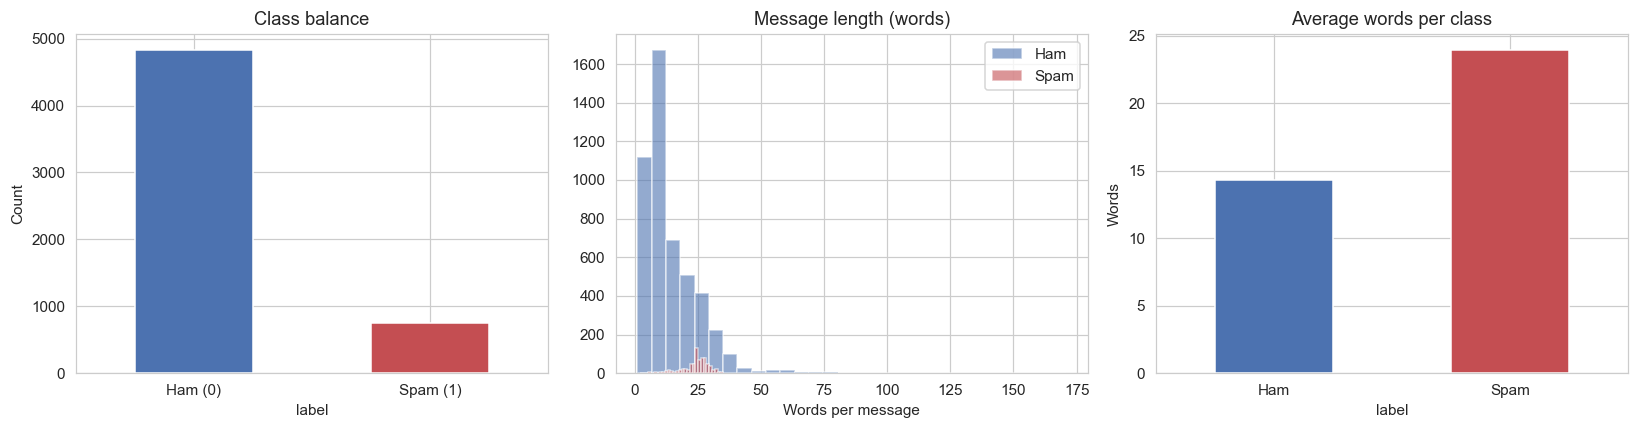

Average words — ham: 14.3 | spam: 23.9


In [7]:
#  EDA
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["label"].value_counts().plot(kind="bar", ax=axes[0],
    color=["#4C72B0", "#C44E52"])
axes[0].set_xticklabels(["Ham (0)", "Spam (1)"], rotation=0)
axes[0].set_title("Class balance"); axes[0].set_ylabel("Count")

for lbl, color in zip([0, 1], ["#4C72B0", "#C44E52"]):
    subset = df[df["label"] == lbl]["n_words"]
    axes[1].hist(subset, bins=30, alpha=0.6, label=f"{'Spam' if lbl else 'Ham'}",
                 color=color)
axes[1].set_title("Message length (words)")
axes[1].set_xlabel("Words per message"); axes[1].legend()

df.groupby("label")["n_words"].mean().plot(kind="bar", ax=axes[2],
    color=["#4C72B0", "#C44E52"])
axes[2].set_xticklabels(["Ham", "Spam"], rotation=0)
axes[2].set_title("Average words per class"); axes[2].set_ylabel("Words")

plt.tight_layout()
plt.savefig("nlp_eda.png", bbox_inches="tight")
plt.show()

print(f"Average words — ham: {df[df.label==0]['n_words'].mean():.1f} | "
      f"spam: {df[df.label==1]['n_words'].mean():.1f}")

In [8]:
# TEXT PREPROCESSING

STOPWORDS = set(stopwords.words("english"))
stemmer   = PorterStemmer()
lemmatizer = WordNetLemmatizer()

URL_RE   = re.compile(r"http\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+")
NUM_RE   = re.compile(r"\d+")
PUNCT_RE = re.compile(f"[{re.escape(string.punctuation)}]")

def preprocess(text, method="lemmatize"):
    """
    method='stem'     → PorterStemmer (fast, crude)
    method='lemmatize'→ WordNetLemmatizer (slower, real words)
    method='both'     → lemma + stem (maximal reduction)
    """
    text = text.lower()
    text = URL_RE.sub(" url ", text)
    text = EMAIL_RE.sub(" email ", text)
    text = NUM_RE.sub(" num ", text)
    text = PUNCT_RE.sub(" ", text)

    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]

    if method == "stem":
        tokens = [stemmer.stem(t) for t in tokens]
    elif method == "lemmatize":
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    elif method == "both":
        tokens = [stemmer.stem(lemmatizer.lemmatize(t)) for t in tokens]

    return " ".join(tokens)

# Side-by-side comparison on one example
sample = df[df.label == 1]["text"].iloc[0]
print("Preprocessing example:")
print(f"raw: {sample[:90]}")
for m in ["stem", "lemmatize", "both"]:
    print(f"   {m:<10}: {preprocess(sample, m)[:90]}")

df["clean_text"] = df["text"].apply(lambda t: preprocess(t, method="lemmatize"))
print("Applied lemmatization to all rows")


Preprocessing example:
raw: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to re
   stem      : free entri num wkli comp win cup final tkt num may num text num receiv entri question std 
   lemmatize : free entry num wkly comp win cup final tkts num may num text num receive entry question st
   both      : free entri num wkli comp win cup final tkt num may num text num receiv entri question std 
Applied lemmatization to all rows


In [9]:
# TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"]
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 4457 | Test: 1115


In [10]:
# TF-IDF VECTORIZATION

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),       # unigrams + bigrams
    max_features=10_000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f" TF-IDF matrix: train={X_train_tfidf.shape}  test={X_test_tfidf.shape}")
print(f"Sample vocab: {list(tfidf.get_feature_names_out())[:10]}")

 TF-IDF matrix: train=(4457, 6888)  test=(1115, 6888)
Sample vocab: ['aah', 'aathi', 'aathi dear', 'aathi love', 'ability', 'abiola', 'abj', 'able', 'able come', 'able deliver']


In [11]:
# TRAIN MODELS

models = {
    "Naive Bayes":        MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=5.0,
                                              random_state=RANDOM_STATE),
    "Linear SVC":         CalibratedClassifierCV(
                              LinearSVC(random_state=RANDOM_STATE), cv=3),
    "Random Forest":      RandomForestClassifier(
                              n_estimators=200, max_depth=20,
                              random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, roc_data = [], {}

print("\n" + "=" * 92)
print(f"{'Model':<22} {'Acc':>7} {'Prec':>7} {'Rec':>7} {'F1':>7} "
      f"{'CV F1':>8} {'AUC':>7}")
print("=" * 92)

for name, clf in models.items():
    clf.fit(X_train_tfidf, y_train)
    y_pred  = clf.predict(X_test_tfidf)
    y_proba = clf.predict_proba(X_test_tfidf)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)

    cv_f1 = cross_val_score(clf, X_train_tfidf, y_train,
                            cv=cv, scoring="f1", n_jobs=-1).mean()

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = (fpr, tpr, roc_auc)
    results.append({
        "Model": name, "Accuracy": acc, "Precision": prec,
        "Recall": rec, "F1": f1, "CV_F1": cv_f1, "AUC": roc_auc,
    })
    print(f"{name:<22} {acc:>7.4f} {prec:>7.4f} {rec:>7.4f} "
          f"{f1:>7.4f} {cv_f1:>8.4f} {roc_auc:>7.4f}")

results_df = (pd.DataFrame(results)
              .sort_values("F1", ascending=False)
              .reset_index(drop=True))
print("=" * 92)
print(f"Best model by F1: {results_df.iloc[0]['Model']}  "
      f"(F1 = {results_df.iloc[0]['F1']:.4f})")


Model                      Acc    Prec     Rec      F1    CV F1     AUC
Naive Bayes             0.9848  0.9648  0.9195  0.9416   0.9362  0.9914
Logistic Regression     0.9883  0.9789  0.9329  0.9553   0.9186  0.9934
Linear SVC              0.9892  0.9660  0.9530  0.9595   0.9371  0.9944
Random Forest           0.9668  1.0000  0.7517  0.8582   0.8444  0.9902
Best model by F1: Linear SVC  (F1 = 0.9595)


In [12]:
# DETAILED CLASSIFICATION REPORT (best model)
best_name = results_df.iloc[0]["Model"]
best_clf  = models[best_name]
y_pred_best = best_clf.predict(X_test_tfidf)

print(f"Classification report — {best_name}:")
print(classification_report(y_test, y_pred_best, target_names=["Ham", "Spam"]))

Classification report — Linear SVC:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



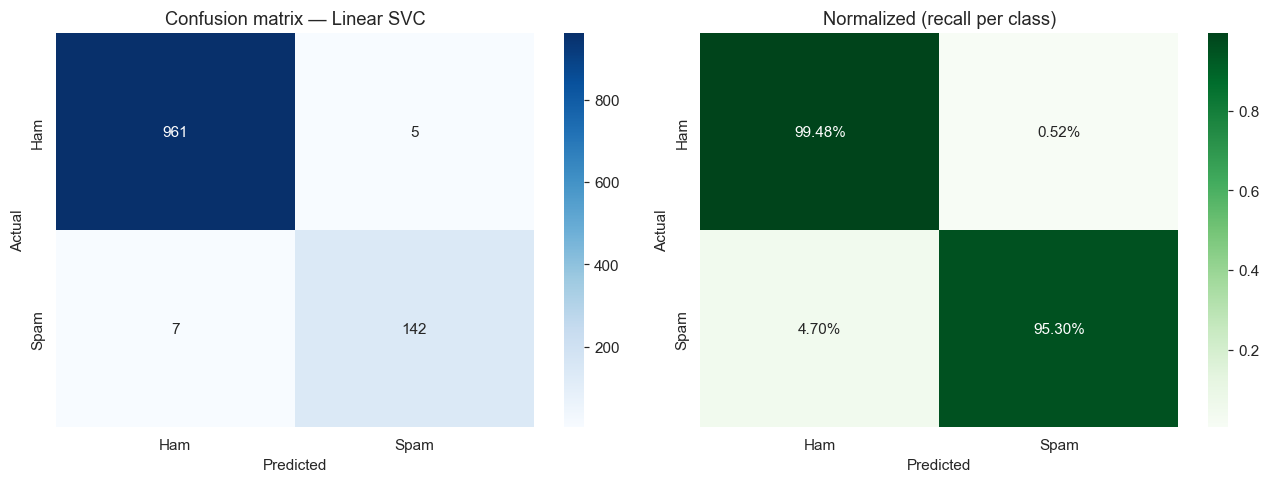

In [13]:
# CONFUSION MATRIX
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[0].set_title(f"Confusion matrix — {best_name}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

# Normalized
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", ax=axes[1],
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
axes[1].set_title("Normalized (recall per class)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("nlp_confusion.png", bbox_inches="tight")
plt.show()

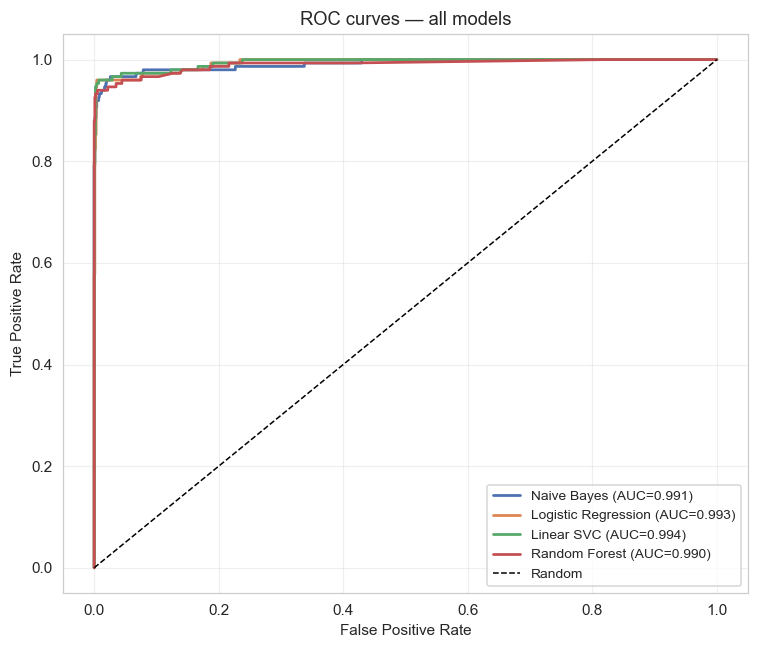

In [14]:
# ROC CURVES

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
for (name, (fpr, tpr, roc_auc)), c in zip(roc_data.items(), colors):
    ax.plot(fpr, tpr, color=c, lw=1.8, label=f"{name} (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — all models")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("nlp_roc.png", bbox_inches="tight")
plt.show()


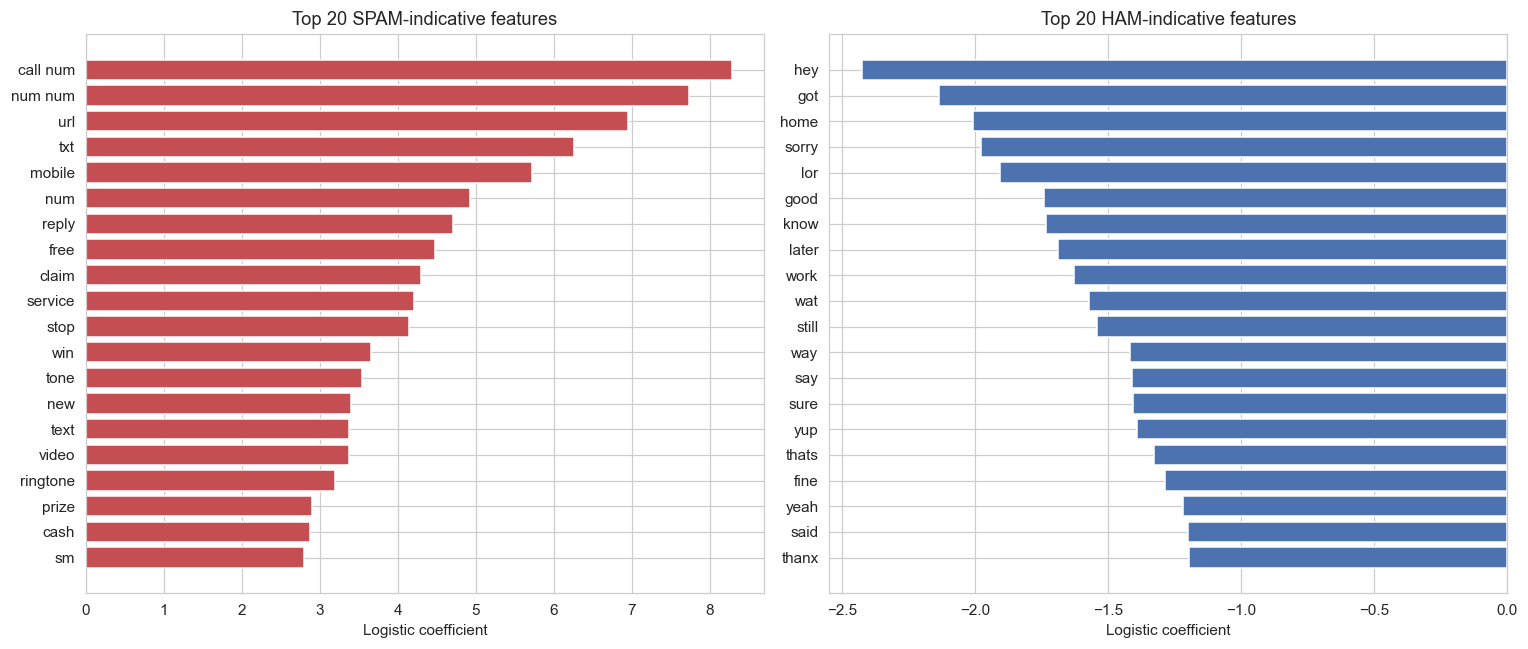

Top 10 spam words: call num, num num, url, txt, mobile, num, reply, free, claim, service
Top 10 ham  words: hey, got, home, sorry, lor, good, know, later, work, wat


In [15]:
# TOP FEATURES PER CLASS (Logistic Regression)

lr = models["Logistic Regression"]
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr.coef_[0]

top_spam = feature_names[np.argsort(coefs)[-20:][::-1]]
top_ham  = feature_names[np.argsort(coefs)[:20]]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(range(20), np.sort(coefs)[-20:][::-1], color="#C44E52")
axes[0].set_yticks(range(20)); axes[0].set_yticklabels(top_spam)
axes[0].invert_yaxis()
axes[0].set_title("Top 20 SPAM-indicative features")
axes[0].set_xlabel("Logistic coefficient")

axes[1].barh(range(20), np.sort(coefs)[:20], color="#4C72B0")
axes[1].set_yticks(range(20)); axes[1].set_yticklabels(top_ham)
axes[1].invert_yaxis()
axes[1].set_title("Top 20 HAM-indicative features")
axes[1].set_xlabel("Logistic coefficient")

plt.tight_layout()
plt.savefig("nlp_top_features.png", bbox_inches="tight")
plt.show()

print("Top 10 spam words:", ", ".join(top_spam[:10]))
print("Top 10 ham  words:", ", ".join(top_ham[:10]))

In [16]:
# END-TO-END PIPELINE (preprocess + TF-IDF + model in one object)

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10_000,
                              min_df=2, sublinear_tf=True)),
    ("clf",   LogisticRegression(max_iter=2000, C=5.0,
                                 random_state=RANDOM_STATE)),
])

final_pipeline.fit(X_train, y_train)   # raw text in, no manual preprocess
final_f1 = f1_score(y_test, final_pipeline.predict(X_test))

print(f" End-to-end pipeline F1: {final_f1:.4f}")

# Example predictions on new, unseen text
new_texts = [
    "Congratulations! You won a free iPhone, click now to claim",
    "Hey, are we still meeting for coffee tomorrow at 10?",
    "URGENT: verify your account now or it will be suspended",
    "Can you send me the report by end of day please",
]
preds = final_pipeline.predict(new_texts)
probs = final_pipeline.predict_proba(new_texts)[:, 1]

print("Live predictions:")
for txt, p, pr in zip(new_texts, preds, probs):
    label = "SPAM " if p == 1 else "HAM "
    print(f" [{label}]  p(spam)={pr:.3f}  ← \"{txt[:60]}\"")

 End-to-end pipeline F1: 0.9553
Live predictions:
 [SPAM ]  p(spam)=0.670  ← "Congratulations! You won a free iPhone, click now to claim"
 [HAM ]  p(spam)=0.002  ← "Hey, are we still meeting for coffee tomorrow at 10?"
 [HAM ]  p(spam)=0.089  ← "URGENT: verify your account now or it will be suspended"
 [HAM ]  p(spam)=0.106  ← "Can you send me the report by end of day please"


In [17]:
# SAVE RESULTS

results_df.to_csv("nlp_metrics.csv", index=False)
import joblib
joblib.dump(final_pipeline, "nlp_spam_pipeline.joblib")

print("Saved:")
for f in ["nlp_eda.png", "nlp_confusion.png", "nlp_roc.png",
          "nlp_top_features.png", "nlp_metrics.csv",
          "nlp_spam_pipeline.joblib"]:
    print(f"   • {f}")

Saved:
   • nlp_eda.png
   • nlp_confusion.png
   • nlp_roc.png
   • nlp_top_features.png
   • nlp_metrics.csv
   • nlp_spam_pipeline.joblib
